# 1. Import required libraries

In [7]:
# Import pandas for creating and handling DataFrames
import pandas as pd

# Import numpy for numerical operations
import numpy as np

# Import matplotlib for plotting graphs
import matplotlib.pyplot as plt

# Import seaborn for statistical visualizations
import seaborn as sns

# Import stats from scipy for calculating Z-scores
from scipy import stats

# 2. Create a sample student marks dataset


In [8]:
# Create a dictionary containing student names and their marks
data = {
    'Student': ['a', 'b', 'c', 'd', 'e',
                'f', 'g', 'h', 'i', 'j',
                'k', 'l', 'm', 'n', 'o',
                'p', 'q', 'r', 's', 't'],

    # Store the marks of 20 students
    'Marks': [45, 55, 60, 52, 65, 70, 68, 72, 75, 62,
              58, 64, 67, 50, 61, 56, 73, 98, 100, 5]
}

# Convert the dictionary into a pandas DataFrame
df = pd.DataFrame(data)

# Display the student marks dataset
print(df)

   Student  Marks
0        a     45
1        b     55
2        c     60
3        d     52
4        e     65
5        f     70
6        g     68
7        h     72
8        i     75
9        j     62
10       k     58
11       l     64
12       m     67
13       n     50
14       o     61
15       p     56
16       q     73
17       r     98
18       s    100
19       t      5


# 3. Visualize data using a box plot

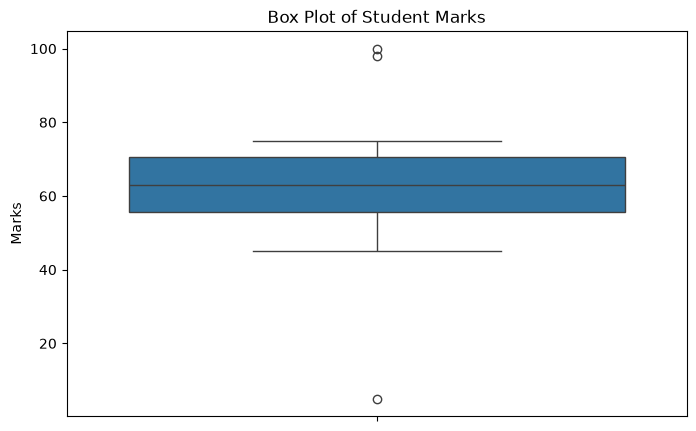

In [9]:
# Set the figure size
plt.figure(figsize=(8, 5))

# Draw a box plot to visualize the distribution of marks
sns.boxplot(y=df['Marks'])

# Add a title to the graph
plt.title("Box Plot of Student Marks")

# Label the y-axis
plt.ylabel("Marks")

# Display the box plot
plt.show()

# 4. Detect outliers using IQR

# Calculate Q1 and Q3


In [10]:
# Calculate the first quartile (25th percentile)
Q1 = df['Marks'].quantile(0.25)

# Calculate the third quartile (75th percentile)
Q3 = df['Marks'].quantile(0.75)

# Display Q1 and Q3
print("Q1 =", Q1)
print("Q3 =", Q3)

Q1 = 55.75
Q3 = 70.5


# Calculate IQR

In [11]:
# Calculate the Interquartile Range
IQR = Q3 - Q1

# Display the IQR value
print("IQR =", IQR)

IQR = 14.75


# Calculate lower and upper limits

In [12]:
# Calculate the lower limit for detecting outliers
lower_limit = Q1 - 1.5 * IQR

# Calculate the upper limit for detecting outliers
upper_limit = Q3 + 1.5 * IQR

# Display both limits
print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

Lower Limit = 33.625
Upper Limit = 92.625


# Identify outliers

In [5]:
# Select marks below the lower limit or above the upper limit
outliers_iqr = df[
    (df['Marks'] < lower_limit) |
    (df['Marks'] > upper_limit)
]

# Display the outliers detected using IQR
print("Outliers detected using IQR:")
print(outliers_iqr)

NameError: name 'lower_limit' is not defined

# 5. Visualize the outliers

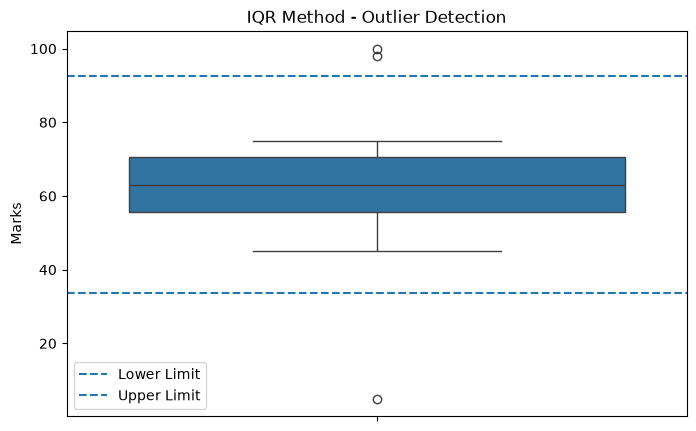

In [8]:
# Set the figure size
plt.figure(figsize=(8, 5))

# Draw a box plot of the original marks
sns.boxplot(y=df['Marks'])

# Draw a dashed line for the lower limit
plt.axhline(lower_limit, linestyle='--', label='Lower Limit')

# Draw a dashed line for the upper limit
plt.axhline(upper_limit, linestyle='--', label='Upper Limit')

# Add the graph title and axis label
plt.title("IQR Method - Outlier Detection")
plt.ylabel("Marks")

# Display the legend
plt.legend()

# Show the graph
plt.show()

# 6. IQR outlier treatment – Capping

In [9]:
# Replace values below the lower limit and above the upper limit
# with the respective boundary values
df['Marks_IQR_Capped'] = df['Marks'].clip(
    lower=lower_limit,
    upper=upper_limit
)

# Display original marks and IQR-capped marks
print(df[['Marks', 'Marks_IQR_Capped']])

    Marks  Marks_IQR_Capped
0      45            45.000
1      55            55.000
2      60            60.000
3      52            52.000
4      65            65.000
5      70            70.000
6      68            68.000
7      72            72.000
8      75            75.000
9      62            62.000
10     58            58.000
11     64            64.000
12     67            67.000
13     50            50.000
14     61            61.000
15     56            56.000
16     73            73.000
17     98            92.625
18    100            92.625
19      5            33.625


# 7. Visualize before and after treatment

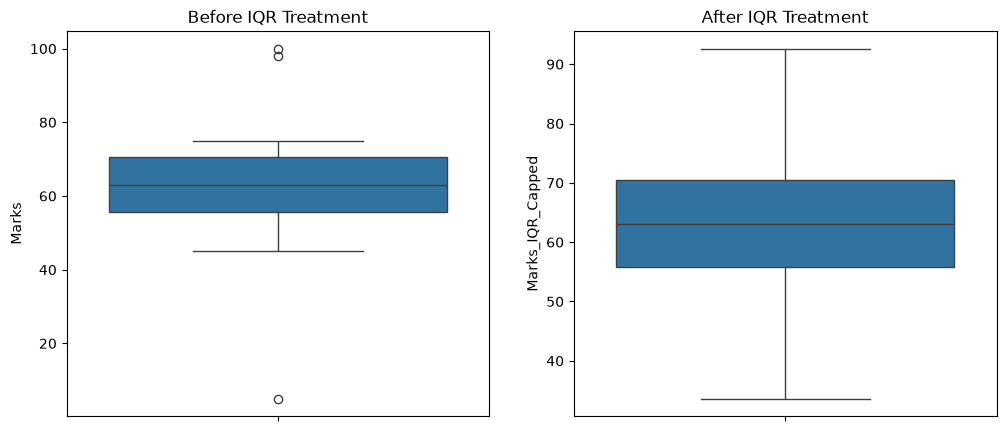

In [10]:
# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Draw a box plot before outlier treatment
sns.boxplot(y=df['Marks'], ax=axes[0])

# Set the title for the first plot
axes[0].set_title("Before IQR Treatment")

# Draw a box plot after IQR capping
sns.boxplot(y=df['Marks_IQR_Capped'], ax=axes[1])

# Set the title for the second plot
axes[1].set_title("After IQR Treatment")

# Display both plots
plt.show()

# 8. Detect outliers using Z-score

In [11]:
# Calculate the Z-score for each student's marks
df['Z_score'] = stats.zscore(df['Marks'])

# Display marks and their corresponding Z-scores
print(df[['Marks', 'Z_score']])

    Marks   Z_score
0      45 -0.941865
1      55 -0.412727
2      60 -0.148159
3      52 -0.571469
4      65  0.116410
5      70  0.380979
6      68  0.275152
7      72  0.486807
8      75  0.645548
9      62 -0.042331
10     58 -0.253986
11     64  0.063497
12     67  0.222238
13     50 -0.677296
14     61 -0.095245
15     56 -0.359814
16     73  0.539720
17     98  1.862564
18    100  1.968392
19      5 -3.058415


# 9. Identify Z-score outliers

In [12]:
# Identify rows where the absolute Z-score is greater than 3
z_outliers = df[abs(df['Z_score']) > 3]

# Display the outliers detected using the Z-score method
print("Outliers detected using Z-score:")
print(z_outliers)

Outliers detected using Z-score:
    Student  Marks  Marks_IQR_Capped   Z_score
19  keerthi      5            33.625 -3.058415


# Display the outlier condition:

In [13]:
# Mark True when the absolute Z-score is greater than 3
df['Z_Outlier'] = abs(df['Z_score']) > 3

# Display marks, Z-scores, and outlier status
print(df[['Marks', 'Z_score', 'Z_Outlier']])

    Marks   Z_score  Z_Outlier
0      45 -0.941865      False
1      55 -0.412727      False
2      60 -0.148159      False
3      52 -0.571469      False
4      65  0.116410      False
5      70  0.380979      False
6      68  0.275152      False
7      72  0.486807      False
8      75  0.645548      False
9      62 -0.042331      False
10     58 -0.253986      False
11     64  0.063497      False
12     67  0.222238      False
13     50 -0.677296      False
14     61 -0.095245      False
15     56 -0.359814      False
16     73  0.539720      False
17     98  1.862564      False
18    100  1.968392      False
19      5 -3.058415       True


# 10. Z-score outlier treatment – Capping

In [14]:
# Calculate the mean of the marks
mean = df['Marks'].mean()

# Calculate the standard deviation of the marks
std = df['Marks'].std()

# Calculate the lower boundary using mean minus 3 standard deviations
lower_z_limit = mean - 3 * std

# Calculate the upper boundary using mean plus 3 standard deviations
upper_z_limit = mean + 3 * std

# Display the Z-score capping limits
print("Lower Z-score limit =", lower_z_limit)
print("Upper Z-score limit =", upper_z_limit)

Lower Z-score limit = 4.631098921918948
Upper Z-score limit = 120.96890107808105


# Cap the values:

In [15]:
# Restrict marks to the calculated lower and upper boundaries
df['Marks_Z_Capped'] = df['Marks'].clip(
    lower=lower_z_limit,
    upper=upper_z_limit
)

# Display original marks and Z-score-capped marks
print(df[['Marks', 'Marks_Z_Capped']])

    Marks  Marks_Z_Capped
0      45              45
1      55              55
2      60              60
3      52              52
4      65              65
5      70              70
6      68              68
7      72              72
8      75              75
9      62              62
10     58              58
11     64              64
12     67              67
13     50              50
14     61              61
15     56              56
16     73              73
17     98              98
18    100             100
19      5               5


# Compare the three versions

In [16]:
# Compare original marks, IQR-capped marks, and Z-score-capped marks
print(df[
    ['Marks', 'Marks_IQR_Capped', 'Marks_Z_Capped']
])

    Marks  Marks_IQR_Capped  Marks_Z_Capped
0      45            45.000              45
1      55            55.000              55
2      60            60.000              60
3      52            52.000              52
4      65            65.000              65
5      70            70.000              70
6      68            68.000              68
7      72            72.000              72
8      75            75.000              75
9      62            62.000              62
10     58            58.000              58
11     64            64.000              64
12     67            67.000              67
13     50            50.000              50
14     61            61.000              61
15     56            56.000              56
16     73            73.000              73
17     98            92.625              98
18    100            92.625             100
19      5            33.625               5


# Visualize the comparison:

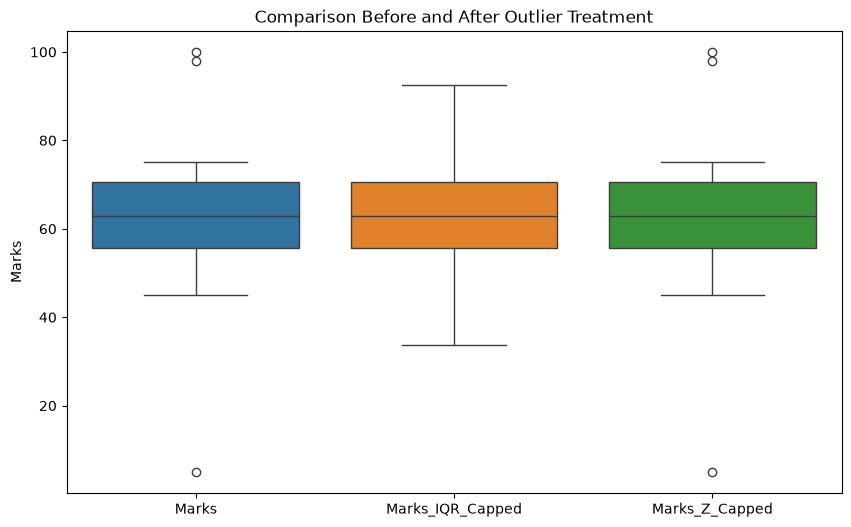

In [17]:
# Set the figure size
plt.figure(figsize=(10, 6))

# Compare the distributions of the original and treated marks
sns.boxplot(data=df[
    ['Marks', 'Marks_IQR_Capped', 'Marks_Z_Capped']
])

# Add the graph title
plt.title("Comparison Before and After Outlier Treatment")

# Label the y-axis
plt.ylabel("Marks")

# Display the comparison graph
plt.show()